# 2.07 · Least squares: the maximum-likelihood answer, and why it is not enough

Least squares is the oldest and most used inversion method in geodesy: fit a velocity to a GPS time series,
fit slip to coseismic offsets (the sudden ground displacements an earthquake produces). This notebook shows what it is (the parameters that make the squared, noise-weighted
misfit smallest), why it is the natural choice (with Gaussian noise it is the maximum-likelihood answer, and among
linear estimators it has the smallest variance), how to check it (χ²), and where it breaks (more unknowns than the
data can see). The break is the reason for priors and regularisation (2.08, 2.09).

**Words this notebook defines:** linear forward model, design matrix, residual, misfit (χ²), normal equations,
weighted least squares, data covariance $\mathbf C_d$, likelihood, maximum likelihood, Gauss-Markov theorem (BLUE),
degrees of freedom, singular value decomposition, ill-posed, null space, truncated SVD, resolution matrix, bias,
mean-squared error, whitening.

**Before this:** [2.03](2-03_probability_distributions.ipynb), [2.04](2-04_conditional_probability.ipynb), [2.06](2-06_matrix_primer.ipynb). · **You will be able to:** set up and solve a weighted least-squares problem;
state exactly what the Gauss-Markov theorem promises and what it does not; check a fit with χ²; recognise an
ill-posed problem from its singular values; compute the answer stably (solve, do not invert). ·
**Optional sections:** 6 (resolution) on a first reading.

**Problems in this notebook**

| problem | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| GPS position series (sections 1-4) | 2 (offset $a$, velocity $b$) | 6 or 12 daily-mean positions | $x(t) = a + b\,t$ | linear |
| antiplane fault (sections 5-6, as in notebook 2.33) | 30 slip patches | 24 stations | screw-dislocation Green's functions, $\mathbf d = \mathbf G\mathbf m$ | linear |

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats as st
import bayeskit as bk
from bayeskit import problems as P, samplers as SM, diagnostics as D, plotting as BP, style as S

TRUE_KW = dict(color="#b5b4ad", lw=4.5, solid_capstyle="round", zorder=1, label="true slip")
np.set_printoptions(precision=4, suppress=True)

## 1. The least-squares answer, worked by hand

**In plain words.** You have a few noisy measurements and a formula that predicts them from a few unknown numbers.
Least squares picks the unknowns whose predictions come closest to the measurements, where "closest" means the sum
of squared differences is smallest. With six positions of a GPS station and the straight line $x(t) = a + b\,t$,
it picks the offset $a$ and the velocity $b$ of the best line.

**Precisely.** A linear forward model is $\mathbf d = \mathbf G\mathbf m + \mathbf e$: data $\mathbf d$ ($N_d$
values), unknowns $\mathbf m$ ($N_m$ values), design matrix $\mathbf G$ ($N_d \times N_m$, one column per unknown)
and noise $\mathbf e$. With equal, independent noise of standard deviation $\sigma$ the least-squares estimate
minimises the misfit $\chi^2(\mathbf m) = \lVert \mathbf d - \mathbf G\mathbf m\rVert^2/\sigma^2$. Setting the
gradient to zero gives the **normal equations**

$$\mathbf G^\top\mathbf G\,\hat{\mathbf m} = \mathbf G^\top\mathbf d, \qquad
\operatorname{Cov}(\hat{\mathbf m}) = \sigma^2(\mathbf G^\top\mathbf G)^{-1}.$$

**Worked example.** Six daily-mean east positions, one per year, noise σ = 3 mm. The design matrix has a column of
ones (for $a$) and a column of times (for $b$). The code prints every step: $\mathbf G^\top\mathbf G$,
$\mathbf G^\top\mathbf d$, the inverse, the estimate, and its covariance.

In [2]:
rng = np.random.default_rng(6)
t6 = np.arange(6.0)                                   # years
a_true, b_true, sig6 = 2.0, 8.0, 3.0                  # mm, mm/yr, mm
x6 = a_true + b_true * t6 + sig6 * rng.standard_normal(t6.size)
G6 = np.column_stack([np.ones_like(t6), t6])
print("data x (mm):", np.round(x6, 2))
print("\nstep 1  G (columns: 1, t):\n", G6)
GtG = G6.T @ G6
Gtd = G6.T @ x6
print("\nstep 2  G^T G = [[N, sum t], [sum t, sum t^2]] =\n", GtG)
print("step 3  G^T d = [sum x, sum t x] =", np.round(Gtd, 3))
det = GtG[0, 0] * GtG[1, 1] - GtG[0, 1] ** 2
inv = np.array([[GtG[1, 1], -GtG[0, 1]], [-GtG[0, 1], GtG[0, 0]]]) / det
print(f"step 4  det(G^T G) = {det:.1f};  (G^T G)^-1 =\n", np.round(inv, 5))
m_hat = inv @ Gtd
print("step 5  estimate m = (G^T G)^-1 G^T d:  a = %.3f mm,  b = %.3f mm/yr   (true %.1f, %.1f)" % (m_hat[0], m_hat[1], a_true, b_true))
C6 = sig6 ** 2 * inv
print("step 6  covariance sigma^2 (G^T G)^-1:\n", np.round(C6, 4))
print("        sd(a) = %.3f mm, sd(b) = %.3f mm/yr, correlation(a, b) = %.3f"
      % (np.sqrt(C6[0, 0]), np.sqrt(C6[1, 1]), C6[0, 1] / np.sqrt(C6[0, 0] * C6[1, 1])))
m_np = np.linalg.lstsq(G6, x6, rcond=None)[0]
print("check   numpy lstsq gives the same estimate:", np.allclose(m_np, m_hat), np.round(m_np, 3))

data x (mm): [ 5.16 15.33 10.34 25.59 37.04 46.06]

step 1  G (columns: 1, t):
 [[1. 0.]
 [1. 1.]
 [1. 2.]
 [1. 3.]
 [1. 4.]
 [1. 5.]]

step 2  G^T G = [[N, sum t], [sum t, sum t^2]] =
 [[ 6. 15.]
 [15. 55.]]
step 3  G^T d = [sum x, sum t x] = [139.513 491.215]
step 4  det(G^T G) = 105.0;  (G^T G)^-1 =
 [[ 0.5238 -0.1429]
 [-0.1429  0.0571]]
step 5  estimate m = (G^T G)^-1 G^T d:  a = 2.905 mm,  b = 8.139 mm/yr   (true 2.0, 8.0)
step 6  covariance sigma^2 (G^T G)^-1:
 [[ 4.7143 -1.2857]
 [-1.2857  0.5143]]
        sd(a) = 2.171 mm, sd(b) = 0.717 mm/yr, correlation(a, b) = -0.826
check   numpy lstsq gives the same estimate: True [2.905 8.139]


saved figures/2-07_line_fit.png


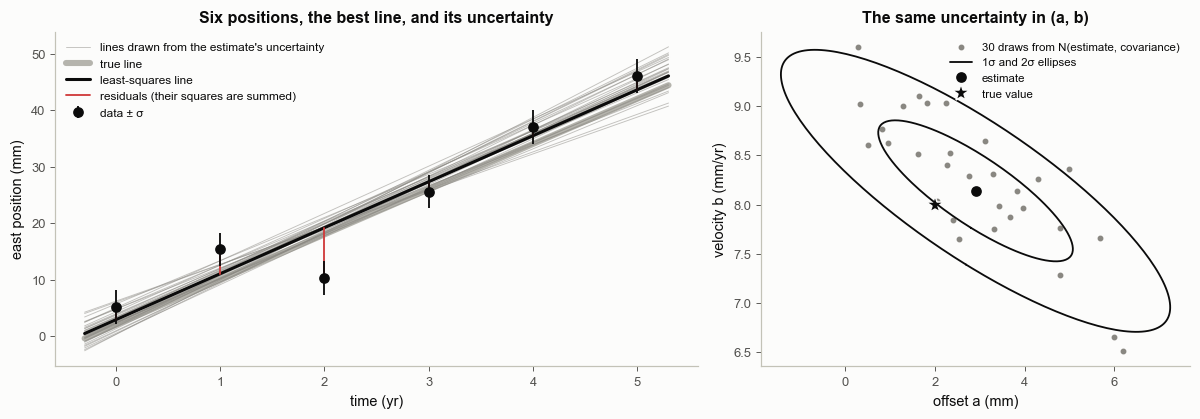

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw=dict(width_ratios=[1.5, 1]))
ax = axs[0]
tt = np.linspace(-0.3, 5.3, 100)
draws = rng.multivariate_normal(m_hat, C6, 30)
for k, (aa, bb) in enumerate(draws):
    ax.plot(tt, aa + bb * tt, color=S.MUTED, lw=0.6, alpha=0.5, label="lines drawn from the estimate's uncertainty" if k == 0 else None)
ax.plot(tt, a_true + b_true * tt, color="#b5b4ad", lw=4, label="true line", zorder=1)
ax.plot(tt, m_hat[0] + m_hat[1] * tt, color=S.INK, lw=2, label="least-squares line")
ax.errorbar(t6, x6, yerr=sig6, fmt="o", color=S.INK, ms=6, capsize=0, lw=1.2, label="data ± σ", zorder=5)
for ti, xi in zip(t6, x6):
    ax.plot([ti, ti], [xi, m_hat[0] + m_hat[1] * ti], color=S.BAD, lw=1.2, zorder=4)
ax.plot([], [], color=S.BAD, lw=1.2, label="residuals (their squares are summed)")
ax.set_xlabel("time (yr)"); ax.set_ylabel("east position (mm)")
ax.set_title("Six positions, the best line, and its uncertainty")
ax.legend(fontsize=7.8, loc="upper left")
ax = axs[1]
ax.scatter(draws[:, 0], draws[:, 1], s=8, color=S.MUTED, label="30 draws from N(estimate, covariance)")
BP.ellipse(ax, m_hat, C6, nsig=1, color=S.INK, lw=1.2, label="1σ and 2σ ellipses")
BP.ellipse(ax, m_hat, C6, nsig=2, color=S.INK, lw=1.2)
ax.plot(*m_hat, "o", color=S.INK, ms=6, label="estimate")
ax.plot(a_true, b_true, "*", color=S.INK, ms=12, mec=S.SURFACE, label="true value")
ax.set_xlabel("offset a (mm)"); ax.set_ylabel("velocity b (mm/yr)")
ax.set_title("The same uncertainty in (a, b)")
ax.legend(fontsize=7.5, loc="upper right")
fig.tight_layout()
bk.savefig(fig, "2-07_line_fit")
plt.show()

**How to read it.** Left: the red segments are the residuals, and least squares makes the sum of their squares
as small as possible. The grey lines are equally acceptable lines given the noise; they fan out away from the
middle of the time span. Right: the same uncertainty in parameter space. The ellipse is tilted because offset and
velocity trade off: a steeper line can be compensated by a lower offset (the correlation is printed above).

**Common misreadings.**
* *"The least-squares line is the true line."* It is the best estimate from these six points; with another noise
  realisation it would move, by about the printed standard deviations.
* *"The uncertainties of $a$ and $b$ can be quoted separately."* They are correlated; quoting both standard
  deviations without the correlation loses the tilt of the ellipse.

**In geodesy.** Station velocities from GPS position time series are exactly this calculation; *trajectory models*
(the full description of a station's motion through time) only add more columns to $\mathbf G$ (seasonal terms,
offsets at earthquakes or equipment changes, logarithmic *postseismic* motion after an earthquake).

## 2. Least squares is maximum likelihood

**In plain words.** Ask a different question: which line makes the six positions we actually measured *most
probable*, if the noise is Gaussian? The answer is the least-squares line. Squaring the residuals is not an
arbitrary choice; it is what Gaussian noise implies.

**Precisely.** With Gaussian noise $\mathbf e \sim N(\mathbf 0, \mathbf C_d)$ the probability density of the data
given the parameters, the **likelihood**, is

$$p(\mathbf d \mid \mathbf m) = (2\pi)^{-N_d/2}\,\lvert\mathbf C_d\rvert^{-1/2}
\exp\!\big[-\tfrac12\,\chi^2(\mathbf m)\big], \qquad
\chi^2(\mathbf m) = (\mathbf d - \mathbf G\mathbf m)^\top\mathbf C_d^{-1}(\mathbf d - \mathbf G\mathbf m).$$

Because $\exp(-\chi^2/2)$ decreases as $\chi^2$ grows, the $\mathbf m$ that maximises the likelihood is the
$\mathbf m$ that minimises $\chi^2$. Two lines whose misfits differ by $\Delta\chi^2$ have a likelihood ratio of
$e^{-\Delta\chi^2/2}$.

saved figures/2-07_likelihood.png


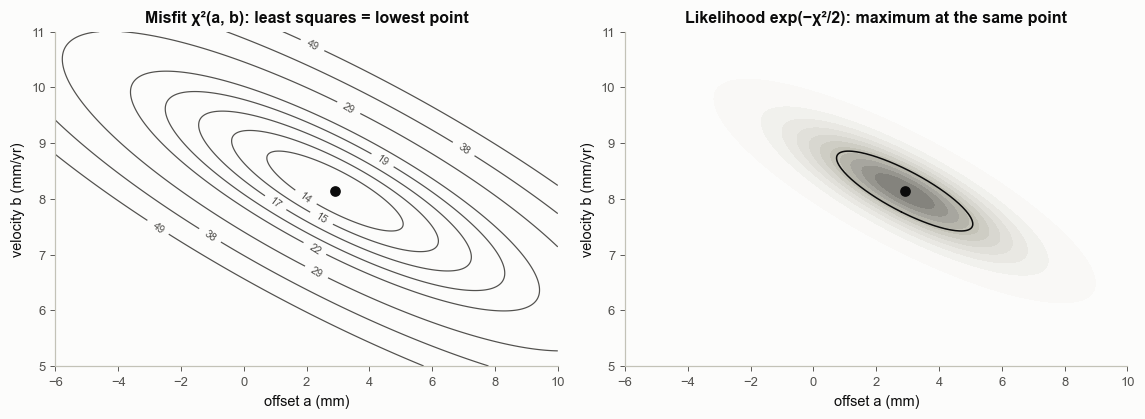

In [4]:
A, B = np.meshgrid(np.linspace(-6, 10, 300), np.linspace(5, 11, 300))
res = x6[None, None, :] - (A[..., None] + B[..., None] * t6[None, None, :])
chi2_grid = np.sum(res ** 2, axis=-1) / sig6 ** 2
lik_grid = np.exp(-0.5 * (chi2_grid - chi2_grid.min()))
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.9))
cs = axs[0].contour(A, B, chi2_grid, levels=chi2_grid.min() + np.array([1, 2.3, 4, 6.2, 9, 16, 25, 36]), colors=S.INK2, linewidths=0.8)
axs[0].clabel(cs, fmt=lambda v: f"{v:.0f}", fontsize=7)
axs[0].plot(*m_hat, "o", color=S.INK, ms=6)
axs[0].set_title("Misfit χ²(a, b): least squares = lowest point")
axs[1].contourf(A, B, lik_grid, levels=np.linspace(0.02, 1, 12), cmap=S.GREYS)
axs[1].plot(*m_hat, "o", color=S.INK, ms=6)
BP.ellipse(axs[1], m_hat, C6, nsig=np.sqrt(st.chi2.ppf(0.393, 2)), color=S.INK, lw=1.0)
axs[1].set_title("Likelihood exp(−χ²/2): maximum at the same point")
for ax in axs:
    ax.set_xlabel("offset a (mm)"); ax.set_ylabel("velocity b (mm/yr)")
fig.tight_layout()
bk.savefig(fig, "2-07_likelihood")
plt.show()

**Worked example.** Evaluate the misfit and the likelihood ratio (relative to the best line) for the best line, the
true line, and a line with the velocity 1 mm/yr higher:

In [5]:
def chi2_line(a, b, sig=sig6):
    return np.sum((x6 - a - b * t6) ** 2) / sig ** 2


for name, (aa, bb) in [("least-squares line", m_hat), ("true line", (a_true, b_true)), ("velocity + 1 mm/yr", (m_hat[0], m_hat[1] + 1))]:
    c2 = chi2_line(aa, bb)
    print(f"{name:20s} a = {aa:6.3f}, b = {bb:6.3f}:  chi^2 = {c2:7.3f},  likelihood ratio to the best = exp(-{(c2 - chi2_line(*m_hat)) / 2:.3f}) = {np.exp(-(c2 - chi2_line(*m_hat)) / 2):.3f}")

least-squares line   a =  2.905, b =  8.139:  chi^2 =  12.576,  likelihood ratio to the best = exp(-0.000) = 1.000
true line            a =  2.000, b =  8.000:  chi^2 =  13.659,  likelihood ratio to the best = exp(-0.541) = 0.582
velocity + 1 mm/yr   a =  2.905, b =  9.139:  chi^2 =  18.688,  likelihood ratio to the best = exp(-3.056) = 0.047


**How to read it.** Left: contours of $\chi^2$ around its minimum. Right: the likelihood, highest at the same
point; the black curve is the 1σ ellipse of section 1, which traces the same shape. The true line is not the most likely one for these data (that is
noise), but its likelihood ratio is not small either: the data do not rule it out.

**Common misreadings.**
* *"The likelihood is the probability of the parameters."* It is the probability (density) of the *data* for given
  parameters. Read as a function of $\mathbf m$ it ranks parameters, but it is not a probability distribution over
  them until a prior is added (2.08).
* *"Least squares assumes nothing."* It is the maximum-likelihood answer only if the noise is Gaussian with the
  covariance you used; with outliers or heavy tails, an L1 misfit is the maximum-likelihood answer for Laplace noise.

## 3. Weighted least squares, $\mathbf C_d$, and the Gauss-Markov theorem

**In plain words.** Some measurements are better than others. A *campaign* occupation (a site visited and measured
for hours to days at a time) is noisier than a continuous station's daily mean. Weighted least squares gives each datum a weight of one over its
noise variance, so precise data pull harder on the answer.

**Precisely.** With noise covariance $\mathbf C_d$ the weighted (generalised) least-squares estimate and its
covariance are

$$\hat{\mathbf m} = (\mathbf G^\top\mathbf C_d^{-1}\mathbf G)^{-1}\mathbf G^\top\mathbf C_d^{-1}\mathbf d, \qquad
\operatorname{Cov}(\hat{\mathbf m}) = (\mathbf G^\top\mathbf C_d^{-1}\mathbf G)^{-1}.$$

**Gauss-Markov theorem.** If the noise has zero mean and known covariance $\mathbf C_d$ (no Gaussian assumption is
needed) and $\mathbf G$ has full column rank (no combination of unknowns is invisible to the data; section 5), this
estimator has the smallest covariance among all *linear unbiased* estimators: it is the best linear unbiased
estimator (BLUE). *Linear* means the estimate is a fixed matrix times the data; *unbiased* means its average over
many repeats of the experiment equals the true value; the **bias** is the difference between that average and the
true value. If the noise is also Gaussian, it is the
maximum-likelihood estimator, and it has the smallest covariance among *all unbiased* estimators, linear or not.

What neither statement says: that it is the best estimator of all. Both compare it only with **unbiased**
estimators. An estimator that is biased on purpose, pulling the answer toward a guess, can have a smaller
**mean-squared error** (spread plus bias², around the true value). The worked example after the next figure shows
this; regularisation and priors (2.08, 2.09) are exactly such deliberate biases.

**Worked example.** Twelve positions, one every three months: four come from campaign occupations (σ = 8 mm), eight from a continuous
station (σ = 1.5 mm). We repeat the experiment 4000 times with new noise, estimate the velocity by ordinary least
squares (equal weights) and by weighted least squares, and compare the scatter of the two estimates with what each
method *reports* about its own uncertainty.

In [6]:
t12 = np.arange(12) / 12.0 * 3.0                                   # 12 epochs over 3 years
sig12 = np.where(np.isin(np.arange(12), [0, 3, 7, 10]), 8.0, 1.5)  # campaign epochs are noisy
G12 = np.column_stack([np.ones_like(t12), t12])
Cd12_inv = np.diag(1 / sig12 ** 2)
W_ols = np.linalg.solve(G12.T @ G12, G12.T)                        # m = W d
W_wls = np.linalg.solve(G12.T @ Cd12_inv @ G12, G12.T @ Cd12_inv)
rng_r = np.random.default_rng(12)
X12 = a_true + b_true * t12 + sig12 * rng_r.standard_normal((4000, 12))
b_ols, b_wls = (X12 @ W_ols.T)[:, 1], (X12 @ W_wls.T)[:, 1]
Cd12 = np.diag(sig12 ** 2)
sd_ols_true = np.sqrt((W_ols @ Cd12 @ W_ols.T)[1, 1])             # what OLS actually scatters by
sd_wls_true = np.sqrt(np.linalg.inv(G12.T @ Cd12_inv @ G12)[1, 1])
sig_avg = np.sqrt(np.mean(sig12 ** 2))
sd_ols_reported = np.sqrt(sig_avg ** 2 * np.linalg.inv(G12.T @ G12)[1, 1])   # what OLS says with one average sigma
print("velocity estimates over 4000 repeated experiments (true b = %.1f mm/yr)" % b_true)
print(f"  ordinary LS : mean {b_ols.mean():.3f}, scatter {b_ols.std():.3f} mm/yr  (theory {sd_ols_true:.3f}); it REPORTS {sd_ols_reported:.3f} using one average sigma")
print(f"  weighted LS : mean {b_wls.mean():.3f}, scatter {b_wls.std():.3f} mm/yr  (theory {sd_wls_true:.3f}); it reports {sd_wls_true:.3f}")
print(f"  ratio of scatters OLS / WLS = {b_ols.std() / b_wls.std():.2f}")

velocity estimates over 4000 repeated experiments (true b = 8.0 mm/yr)
  ordinary LS : mean 7.981, scatter 1.733 mm/yr  (theory 1.761); it REPORTS 1.598 using one average sigma
  weighted LS : mean 8.011, scatter 0.647 mm/yr  (theory 0.648); it reports 0.648
  ratio of scatters OLS / WLS = 2.68


saved figures/2-07_weighted.png


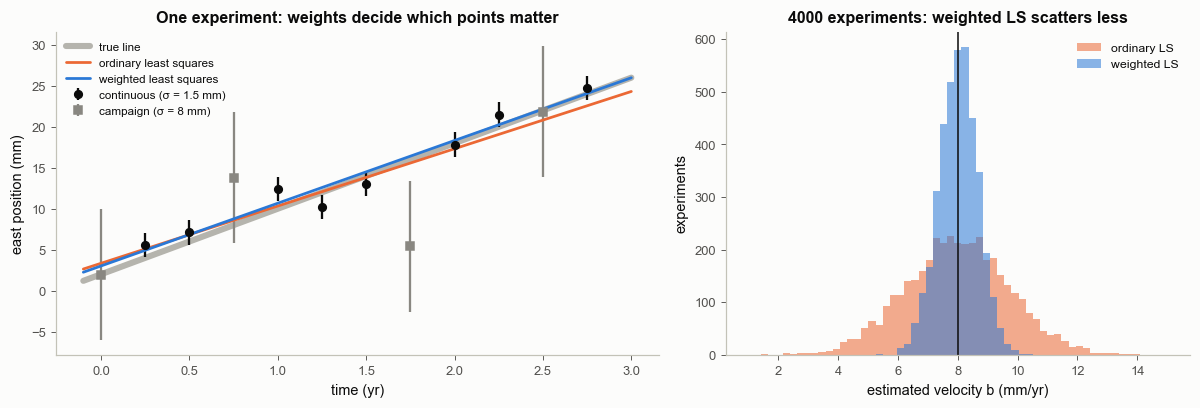

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw=dict(width_ratios=[1.3, 1]))
ax = axs[0]
x_one = X12[0]
m_o, m_w = W_ols @ x_one, W_wls @ x_one
noisy = sig12 > 2
ax.errorbar(t12[~noisy], x_one[~noisy], yerr=sig12[~noisy], fmt="o", color=S.INK, ms=5, capsize=0, label="continuous (σ = 1.5 mm)")
ax.errorbar(t12[noisy], x_one[noisy], yerr=sig12[noisy], fmt="s", color=S.MUTED, ms=5, capsize=0, label="campaign (σ = 8 mm)")
tt = np.linspace(-0.1, 3.0, 50)
ax.plot(tt, a_true + b_true * tt, color="#b5b4ad", lw=4, zorder=0, label="true line")
ax.plot(tt, m_o[0] + m_o[1] * tt, color=S.ORANGE, lw=1.8, label="ordinary least squares")
ax.plot(tt, m_w[0] + m_w[1] * tt, color=S.BLUE, lw=1.8, label="weighted least squares")
ax.set_xlabel("time (yr)"); ax.set_ylabel("east position (mm)")
ax.set_title("One experiment: weights decide which points matter")
ax.legend(fontsize=7.6, loc="upper left")
ax = axs[1]
bins = np.linspace(b_true - 4 * sd_ols_true, b_true + 4 * sd_ols_true, 60)
ax.hist(b_ols, bins=bins, color=S.ORANGE, alpha=0.55, label="ordinary LS")
ax.hist(b_wls, bins=bins, color=S.BLUE, alpha=0.55, label="weighted LS")
ax.axvline(b_true, color=S.INK, lw=1)
ax.set_xlabel("estimated velocity b (mm/yr)"); ax.set_ylabel("experiments")
ax.set_title("4000 experiments: weighted LS scatters less")
ax.legend(fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-07_weighted")
plt.show()

**How to read it.** Both estimators are unbiased (their means sit on the true velocity), but the weighted one
scatters less, as Gauss-Markov promises. Worse than the extra scatter: ordinary least squares with one average σ
*reports* an uncertainty that does not match its actual scatter (compare the printed numbers). The error is in the
reported uncertainty, not only in the estimate.

**Common misreadings.**
* *"Weighting changes the answer a little, so it hardly matters."* It matters most for the uncertainty you report.
* *"Least squares needs Gaussian noise."* The BLUE property needs only zero-mean noise with known covariance;
  Gaussianity is what makes it the maximum-likelihood answer as well.

**Unbiased is not the same as best.** One measurement $y = \theta + e$, $e \sim N(0, 1)$. The unbiased estimate
$\hat\theta = y$ has mean-squared error 1 whatever θ is. The shrunk estimate $\hat\theta = y/2$ is biased (its mean is
θ/2) but has half the spread; its mean-squared error is $1/4 + \theta^2/4$. Below $|\theta| = \sqrt 3$ the biased
estimate wins. The cell checks both formulas by simulation.

In [8]:
rng_b = np.random.default_rng(7)
for theta in (0.0, 1.0, 2.0):
    yb = theta + rng_b.standard_normal(200_000)
    print(f"theta = {theta:.0f}:  MSE of y   = {np.mean((yb - theta) ** 2):.3f} (formula 1.000);"
          f"  MSE of y/2 = {np.mean((yb / 2 - theta) ** 2):.3f} (formula {0.25 + theta ** 2 / 4:.3f})")
print(f"the biased estimate y/2 has the smaller MSE while |theta| < sqrt(3) = {np.sqrt(3):.3f}")

theta = 0:  MSE of y   = 0.998 (formula 1.000);  MSE of y/2 = 0.250 (formula 0.250)
theta = 1:  MSE of y   = 0.997 (formula 1.000);  MSE of y/2 = 0.499 (formula 0.500)
theta = 2:  MSE of y   = 1.002 (formula 1.000);  MSE of y/2 = 1.247 (formula 1.250)
the biased estimate y/2 has the smaller MSE while |theta| < sqrt(3) = 1.732


So "least squares is optimal" always needs its qualifier: *among unbiased estimators*. When the data cannot pin
the parameters down (section 5), the unbiased answer has an enormous spread, and accepting some bias for a much
smaller spread is the better trade. That is the step from least squares to Bayesian inversion (2.08).

**In geodesy.** $\mathbf C_d$ is where measurement quality enters every inversion: different σ for horizontal and
vertical GNSS, for campaign and continuous sites, for InSAR (satellite radar maps of ground displacement along the
line of sight) and tide gauges. When two data sets have unknown relative
quality, an inversion can estimate one noise scale $\sigma_k$ per data set instead of fixing the weights (2.13 and
2.30 come back to this).

## 4. χ²: is the fit as good as the noise allows?

**In plain words.** If the model is right and the noise level σ is right, each residual divided by σ is typically
between −1 and +1, so the sum of their squares is about the number of data minus the number of fitted parameters.
Much larger means the model or σ is wrong (the residuals are bigger than the noise); much smaller means σ is too
large, and the reported uncertainties are too wide.

**Precisely.** If $\mathbf e \sim N(\mathbf 0, \mathbf C_d)$ and the model is correct, the misfit at the
least-squares estimate follows a chi-square distribution with $\nu = N_d - N_m$ degrees of freedom (mean $\nu$,
standard deviation $\sqrt{2\nu}$). The *reduced* chi-square $\chi^2/\nu$ should be close to 1.

**Worked example.** The same twelve epochs with equal noise σ = 3 mm, fitted three times: with the right σ, with σ
assumed three times too small, and three times too large. The least-squares line does not change (with equal
weights σ cancels out of the estimate), but $\chi^2/\nu$ and the reported uncertainty do.

In [9]:
x12e = a_true + b_true * t12 + 3.0 * np.random.default_rng(4).standard_normal(12)
m12 = np.linalg.lstsq(G12, x12e, rcond=None)[0]
nu = 12 - 2
lo, hi = st.chi2.ppf([0.025, 0.975], nu)
print(f"degrees of freedom nu = {nu}; with correct sigma, chi^2 lies between {lo:.1f} and {hi:.1f} in 95 % of experiments")
assumed = [1.0, 3.0, 9.0]
for sa in assumed:
    c2 = np.sum((x12e - G12 @ m12) ** 2) / sa ** 2
    sdb = np.sqrt(sa ** 2 * np.linalg.inv(G12.T @ G12)[1, 1])
    print(f"assumed sigma = {sa:3.0f} mm (true 3): chi^2 = {c2:7.2f}, chi^2/nu = {c2 / nu:6.3f}, reported sd(b) = {sdb:.3f} mm/yr")
rep = a_true + b_true * t12 + 3.0 * np.random.default_rng(5).standard_normal((5000, 12))
mrep = np.linalg.lstsq(G12, rep.T, rcond=None)[0].T
chi2_rep = np.sum((rep - mrep @ G12.T) ** 2, axis=1) / 9.0
print(f"over 5000 repeats with the correct sigma: mean chi^2 = {chi2_rep.mean():.2f} (theory {nu}), sd = {chi2_rep.std():.2f} (theory {np.sqrt(2 * nu):.2f})")

degrees of freedom nu = 10; with correct sigma, chi^2 lies between 3.2 and 20.5 in 95 % of experiments
assumed sigma =   1 mm (true 3): chi^2 =  105.35, chi^2/nu = 10.535, reported sd(b) = 0.334 mm/yr
assumed sigma =   3 mm (true 3): chi^2 =   11.71, chi^2/nu =  1.171, reported sd(b) = 1.003 mm/yr
assumed sigma =   9 mm (true 3): chi^2 =    1.30, chi^2/nu =  0.130, reported sd(b) = 3.010 mm/yr
over 5000 repeats with the correct sigma: mean chi^2 = 9.95 (theory 10), sd = 4.45 (theory 4.47)


saved figures/2-07_chi2.png


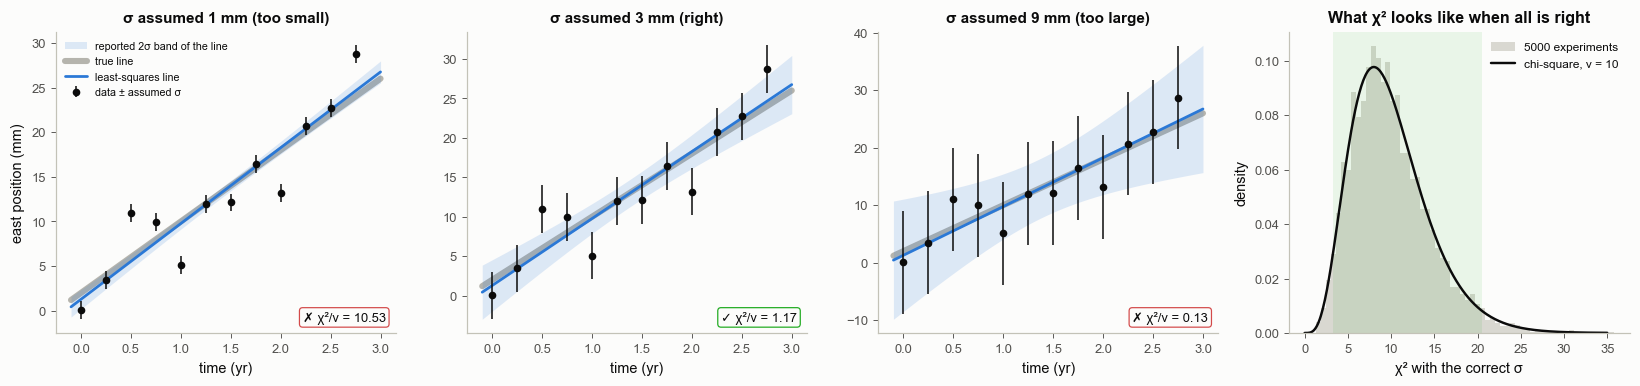

In [10]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.6))
tt = np.linspace(-0.1, 3.0, 50)
for ax, sa, title in zip(axs[:3], assumed, ["σ assumed 1 mm (too small)", "σ assumed 3 mm (right)", "σ assumed 9 mm (too large)"]):
    Cm = sa ** 2 * np.linalg.inv(G12.T @ G12)
    band = np.sqrt(np.einsum("ij,jk,ik->i", np.column_stack([np.ones_like(tt), tt]), Cm, np.column_stack([np.ones_like(tt), tt])))
    fitl = m12[0] + m12[1] * tt
    ax.fill_between(tt, fitl - 2 * band, fitl + 2 * band, color=S.BLUE, alpha=0.15, lw=0, label="reported 2σ band of the line")
    ax.plot(tt, a_true + b_true * tt, color="#b5b4ad", lw=4, zorder=0, label="true line")
    ax.plot(tt, fitl, color=S.BLUE, lw=1.8, label="least-squares line")
    ax.errorbar(t12, x12e, yerr=sa, fmt="o", color=S.INK, ms=4, capsize=0, lw=1, label="data ± assumed σ")
    c2 = np.sum((x12e - G12 @ m12) ** 2) / sa ** 2
    S.badge(ax, f"χ²/ν = {c2 / nu:.2f}", ok=lo / nu <= c2 / nu <= hi / nu, loc="lower right", fs=8.5)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("time (yr)")
axs[0].set_ylabel("east position (mm)")
axs[0].legend(fontsize=7, loc="upper left")
ax = axs[3]
ax.hist(chi2_rep, bins=60, density=True, color="#d9d8d1", label="5000 experiments")
xx = np.linspace(0, 35, 300)
ax.plot(xx, st.chi2.pdf(xx, nu), color=S.INK, lw=1.6, label=f"chi-square, ν = {nu}")
ax.axvspan(lo, hi, color=S.GOOD, alpha=0.08, lw=0)
ax.set_xlabel("χ² with the correct σ"); ax.set_ylabel("density")
ax.set_title("What χ² looks like when all is right")
ax.legend(fontsize=7.8)
fig.tight_layout()
bk.savefig(fig, "2-07_chi2")
plt.show()

**How to read it.** The three fits are the same line; only the claimed noise differs. With σ too small, $\chi^2/\nu$
is far above 1 and the band is too narrow: the line is overconfident. With σ too large, $\chi^2/\nu$ is far below 1
and the band is too wide. Right panel: with the correct σ, $\chi^2$ scatters around $\nu$ by about
$\sqrt{2\nu}$, so a single value between the shaded limits is consistent with a correct σ.

**Common misreadings.**
* *"$\chi^2/\nu \ll 1$ means an excellent fit."* It means σ is too large, so residuals are small *relative to
  σ*. A fit can be visibly poor and still have $\chi^2/\nu \ll 1$ if σ is loose: always look at the residuals.
* *"χ² only tests σ."* It tests σ and the model together. A wrong model (for example a straight line through data that
  curve) also inflates $\chi^2$, and χ² alone cannot tell which of the two is wrong.

**In practice.** When several inversions are compared, report the weighted RMS misfit (the root-mean-square of the
residuals, each divided by its σ) *and* $\chi^2/N$ for each data set, and plot the fits: a σ that is too loose gives $\chi^2/N \ll 1$ even when a waveform fit is visibly poor.

## 5. When least squares fails: more unknowns than the data can see

**In plain words.** The fault of notebook 2.33 is an *antiplane* fault: a long, vertical strike-slip fault whose slip
varies only with depth, so that the problem is two-dimensional and each patch's surface signal has a simple formula
(a screw dislocation). It has 30 slip patches and 24 stations, but the stations sit in mirror pairs on the two sides
of the fault, and the fault moves the two sides by equal and opposite amounts. Each
pair therefore measures the same thing twice: the 24 stations see only 12 independent combinations of slip (the
pairs average the noise down, but add no new combination). Deep patches also produce almost identical, weak surface
signals. So many very different slip models predict the data equally well, and some slip patterns produce no
surface signal at all. Least squares has no way to choose among them, and it amplifies noise enormously while trying
to fit every wiggle. A problem whose answer is not unique, or changes wildly with tiny changes in the data, is called
**ill-posed**; most slip inversions are.

**Precisely.** The **singular value decomposition** (SVD) $\mathbf G = \mathbf U\boldsymbol\Sigma\mathbf V^\top$ writes the
forward model as independent channels: slip pattern $\mathbf v_i$ (a column of $\mathbf V$) produces data pattern
$\mathbf u_i$ (a column of $\mathbf U$) amplified by the gain $s_i$, the $i$-th **singular value** (written $s_i$ here, because σ is the data noise):
$\mathbf G\mathbf v_i = s_i\mathbf u_i$. The patterns in each set are *orthonormal* (each of unit length, every two
perpendicular), so the channels do not mix, and the gains are sorted from strongest to weakest. The figure after the
next cell draws four channels. The **minimum-norm** least-squares solution (of all equally good fits, the one with the
smallest total size $\lVert\mathbf m\rVert$) is

$$\hat{\mathbf m} = \sum_i \frac{\mathbf u_i^\top\mathbf d}{s_i}\,\mathbf v_i .$$

Noise contributes about $\sigma$ (the data noise) to each $\mathbf u_i^\top\mathbf d$, so channel $i$ carries
noise $\sigma/s_i$ into the slip: channels with $s_i$ below the noise level are mostly noise. The number of
nonzero $s_i$ is the **rank** of $\mathbf G$; the remaining $N_m - \text{rank}$ patterns (the **null space**)
produce no data at all. A problem like this is **ill-posed**. **Truncated SVD** keeps only the $k$ strongest
channels.

In [11]:
Nf = 30
z_edges = np.linspace(0.0, 30.0, Nf + 1)
zc = 0.5 * (z_edges[1:] + z_edges[:-1])
xs = np.array([1, 2, 3, 4, 6, 9, 13, 18, 25, 35, 50, 70.0])
xs = np.sort(np.r_[-xs, xs])                                       # 24 stations, both sides (km)


def patch_disp(x, z1, z2):
    """Surface displacement per unit slip from a patch between depths z1 and z2 (screw dislocation; Segall 2010)."""
    return (np.arctan(z2 / x) - np.arctan(z1 / x)) / np.pi


Gf = 1000.0 * np.array([[patch_disp(x, z_edges[j], z_edges[j + 1]) for j in range(Nf)] for x in xs])   # mm per m
s_true = 2.0 * np.exp(-0.5 * ((zc - 12.0) / 4.0) ** 2)                                                  # m
sig_f = 3.0
d_f = Gf @ s_true + sig_f * np.random.default_rng(42).standard_normal(xs.size)
U, sv, Vt = np.linalg.svd(Gf, full_matrices=True)
pair = np.abs(Gf[:12][::-1] + Gf[12:]).max()                       # station -x vs +x (rows sorted west to east)
print(f"mirror stations: max |G(-x) + G(x)| = {pair:.1e} mm/m, so each pair records the same combination with opposite sign")
rank = int(np.sum(sv > sv[0] * 1e-10))
print(f"G is {Gf.shape[0]} x {Gf.shape[1]} but has rank {rank}: the singular values after number {rank} are round-off (largest of them {sv[rank]:.1e})")
print(f"so {Nf - rank} independent slip patterns are exactly invisible (the null space)")
print(f"singular values: largest {sv[0]:.1f}, smallest nonzero {sv[rank - 1]:.2e} mm per m; {np.sum(sv > sig_f)} of {rank} exceed the noise level {sig_f:.0f} mm")
v_null = Vt[-1]
print(f"a null-space slip pattern v: max |G v| = {np.abs(Gf @ v_null).max():.1e} mm for a pattern with max |v| = {np.abs(v_null).max():.2f} m")
print(f"adding 5 v to the true slip changes the predicted data by at most {np.abs(Gf @ (5 * v_null)).max():.1e} mm")


def tsvd(k):
    return Vt[:k].T @ ((U[:, :k].T @ d_f) / sv[:k])


print("\n  k   rms error vs true slip (m)   max |slip| (m)   chi^2 of the fit (24 data)")
tsvd_rows = {}
for k in [3, 5, 6, 8, 10, 12]:
    mk = tsvd(k)
    tsvd_rows[k] = mk
    print(f"{k:3d}   {np.sqrt(np.mean((mk - s_true) ** 2)):24.3f}   {np.abs(mk).max():14.2f}   {np.sum(((d_f - Gf @ mk) / sig_f) ** 2):10.2f}")

mirror stations: max |G(-x) + G(x)| = 0.0e+00 mm/m, so each pair records the same combination with opposite sign
G is 24 x 30 but has rank 12: the singular values after number 12 are round-off (largest of them 1.8e-14)
so 18 independent slip patterns are exactly invisible (the null space)
singular values: largest 591.2, smallest nonzero 1.06e-04 mm per m; 5 of 12 exceed the noise level 3 mm
a null-space slip pattern v: max |G v| = 1.8e-15 mm for a pattern with max |v| = 0.38 m
adding 5 v to the true slip changes the predicted data by at most 8.9e-15 mm

  k   rms error vs true slip (m)   max |slip| (m)   chi^2 of the fit (24 data)
  3                      0.537             1.13       101.11
  5                      0.314             1.74        17.41
  6                      0.240             1.80        15.20
  8                      3.505             6.77        12.64
 10                     93.887           221.36         8.13
 12                   6370.487         13363.05         

**The SVD, drawn.** Each column below is one channel $i$: the slip pattern $\mathbf v_i$ (top, slip against depth), the
data pattern $\mathbf u_i$ it produces at the stations (bottom, against station position), and its gain $s_i$.
Slip along $\mathbf v_i$ appears in the data as $s_i\mathbf u_i$, and nothing else.

saved figures/2-07_svd_channels.png


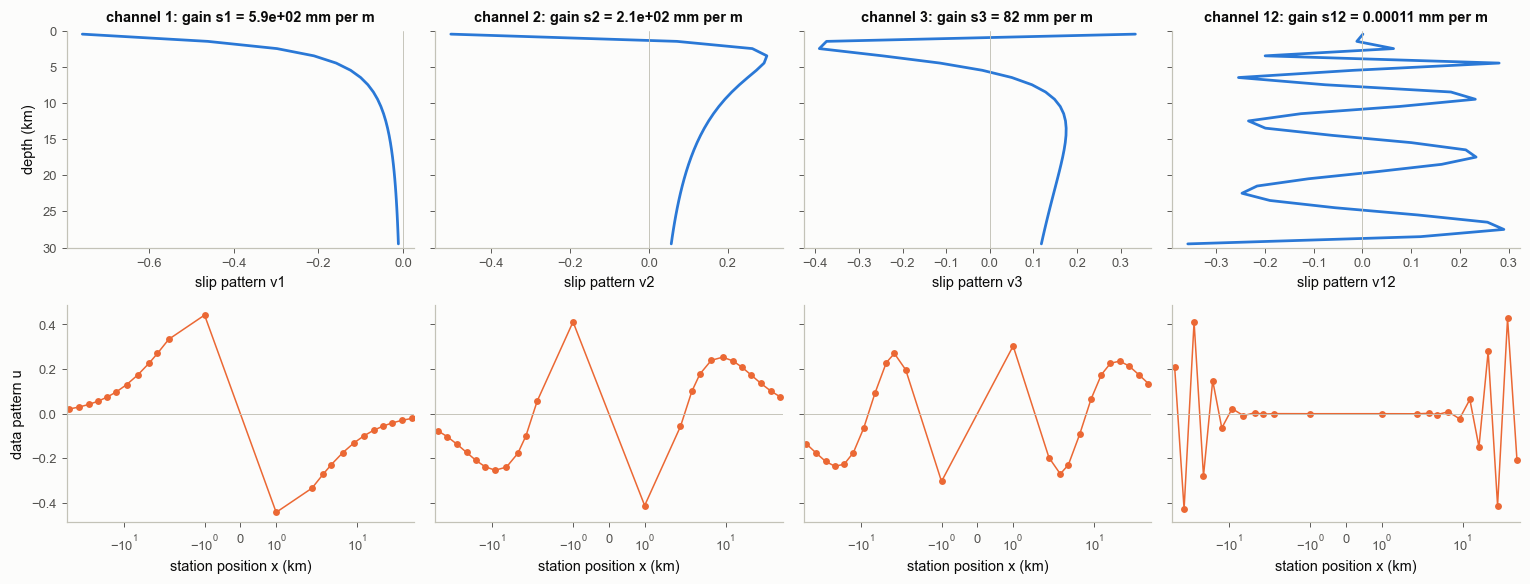

In [12]:
fig, axs = plt.subplots(2, 4, figsize=(14, 5.4), sharey="row")
for col, i in enumerate([0, 1, 2, rank - 1]):
    axs[0, col].plot(Vt[i], zc, color=S.BLUE, lw=1.8)
    axs[0, col].axvline(0, color=S.AXIS, lw=0.6)
    axs[0, col].set_ylim(30, 0)
    axs[0, col].set_title(f"channel {i + 1}: gain s{i + 1} = {sv[i]:.2g} mm per m", fontsize=9.5)
    axs[0, col].set_xlabel(f"slip pattern v{i + 1}")
    axs[1, col].plot(xs, U[:, i], "o-", color=S.ORANGE, ms=3.5, lw=1)
    axs[1, col].axhline(0, color=S.AXIS, lw=0.6)
    axs[1, col].set_xscale("symlog", linthresh=2)
    axs[1, col].set_xlabel("station position x (km)")
axs[0, 0].set_ylabel("depth (km)")
axs[1, 0].set_ylabel(f"data pattern u")
fig.tight_layout()
bk.savefig(fig, "2-07_svd_channels")
plt.show()

**How to read it.** The strongest channel is a broad shallow slip pattern that moves every station; later channels
alternate in sign with depth and their data patterns wiggle across the stations, so the same amount of slip produces
a smaller and smaller signal (the gains printed in the titles). The weakest channel the stations can see at all
oscillates with depth from top to bottom, its data pattern is nearly zero close to the fault, and its gain is far
below the 3 mm noise. Its slip pattern would be recovered from data that are almost pure noise. (The data patterns
are antisymmetric because mirror stations move by equal and opposite amounts.)

saved figures/2-07_illposed.png


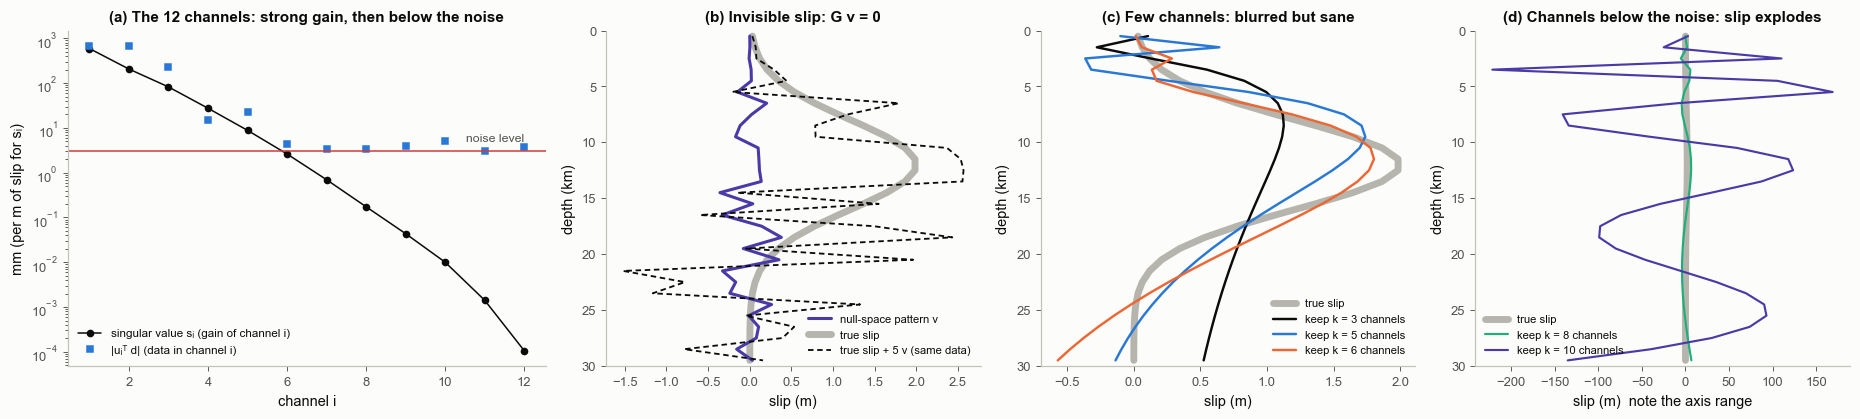

In [13]:
fig, axs = plt.subplots(1, 4, figsize=(17, 3.9), gridspec_kw=dict(width_ratios=[1.15, 0.9, 0.9, 0.9]))
ax = axs[0]
ax.semilogy(np.arange(1, rank + 1), sv[:rank], "o-", color=S.INK, ms=4, lw=1, label="singular value sᵢ (gain of channel i)")
ax.semilogy(np.arange(1, rank + 1), np.abs(U[:, :rank].T @ d_f), "s", color=S.BLUE, ms=4, label="|uᵢᵀ d| (data in channel i)")
ax.axhline(sig_f, color=S.BAD, lw=1)
ax.text(rank, sig_f * 1.7, "noise level", ha="right", fontsize=8, color=S.INK2)
ax.set_xlabel("channel i"); ax.set_ylabel("mm (per m of slip for sᵢ)")
ax.set_title(f"(a) The {rank} channels: strong gain, then below the noise", fontsize=10)
ax.legend(fontsize=7.6, loc="lower left")
ax = axs[1]
ax.plot(v_null, zc, color=S.VIOLET, lw=2, label="null-space pattern v")
ax.plot(s_true, zc, **TRUE_KW)
ax.plot(s_true + 5 * v_null, zc, color=S.INK, lw=1.2, ls=(0, (3, 2)), label="true slip + 5 v (same data)")
ax.set_ylim(30, 0); ax.set_xlabel("slip (m)"); ax.set_ylabel("depth (km)")
ax.set_title("(b) Invisible slip: G v = 0", fontsize=10)
ax.legend(fontsize=7.4, loc="lower right")
ax = axs[2]
ax.plot(s_true, zc, **TRUE_KW)
for k, c in [(3, S.INK), (5, S.BLUE), (6, S.ORANGE)]:
    ax.plot(tsvd_rows[k], zc, color=c, lw=1.6, label=f"keep k = {k} channels")
ax.set_ylim(30, 0); ax.set_xlabel("slip (m)"); ax.set_ylabel("depth (km)")
ax.set_title("(c) Few channels: blurred but sane", fontsize=10)
ax.legend(fontsize=7.4, loc="lower right")
ax = axs[3]
ax.plot(s_true, zc, **TRUE_KW)
for k, c in [(8, S.AQUA), (10, S.VIOLET)]:
    ax.plot(tsvd_rows[k], zc, color=c, lw=1.4, label=f"keep k = {k} channels")
ax.set_ylim(30, 0); ax.set_xlabel("slip (m)  note the axis range"); ax.set_ylabel("depth (km)")
ax.set_title("(d) Channels below the noise: slip explodes", fontsize=10)
ax.legend(fontsize=7.4, loc="lower left")
fig.tight_layout()
bk.savefig(fig, "2-07_illposed")
plt.show()

**How to read it.** Left: the gains $s_i$ of the channels the stations can see fall by orders of magnitude, and
the blue squares (the data in each channel) sink to the noise level after a few channels: beyond that point the data
contain no information, only noise.
Middle: a slip pattern the stations cannot see at all; adding it to the true slip changes no prediction (printed
above), so the data cannot tell these two slip models apart. (c): keeping the channels above the noise gives a
smooth, blurred version of the truth. (d): keeping channels below the noise lets noise in, divided by tiny gains,
and the slip explodes (note the axis range). The table above shows the trade: as $k$ grows, $\chi^2$ falls (a
better fit) while the error against the true slip first falls, then grows.

**Worked example.** One channel by hand: the noise in $\mathbf u_i^\top\mathbf d$ has standard deviation σ, so the
slip it injects along $\mathbf v_i$ has standard deviation $\sigma/s_i$:

In [14]:
for i in [0, 4, 7, 11]:
    print(f"channel {i + 1:2d}: gain {sv[i]:10.4f} mm/m  ->  noise injected into slip {sig_f / sv[i]:10.3f} m")

channel  1: gain   591.2421 mm/m  ->  noise injected into slip      0.005 m
channel  5: gain     8.8157 mm/m  ->  noise injected into slip      0.340 m
channel  8: gain     0.1735 mm/m  ->  noise injected into slip     17.296 m
channel 12: gain     0.0001 mm/m  ->  noise injected into slip  28270.633 m


**Common misreadings.**
* *"A perfect fit is the best model."* Driving $\chi^2$ far below $\nu$ means fitting the noise; the model that does
  it here is wildly wrong (table above).
* *"The minimum-norm solution is what the data say."* It is one choice among infinitely many that fit equally well:
  it sets every invisible pattern to zero. That choice is a prior in disguise, and 2.08 makes priors explicit.

## 6. Resolution: each estimated patch is a blurred average of the true ones

**In plain words.** With truncated SVD (or any regularisation), the estimate at one patch is not the true slip
there; it is a weighted average of the true slip over neighbouring patches, plus noise. The weights form a
blurring kernel, one per patch. Shallow patches have sharp kernels; deep patches have broad ones.

**Precisely.** For truncated SVD, $\mathbb E[\hat{\mathbf m}] = \mathbf R\,\mathbf m_{\text{true}}$ with the
**resolution matrix** $\mathbf R = \mathbf V_k\mathbf V_k^\top$ ($\mathbf V_k$: the first $k$ slip patterns). Row $j$ is
the blurring kernel of patch $j$; a perfectly resolved patch has a row equal to 1 at $j$ and 0 elsewhere. The trace of
$\mathbf R$ (the sum of its diagonal) is $k$, the number of independent slip combinations the data determine.

truncated SVD with k = 6: trace(R) = 6.00
patch at  1.5 km: diagonal R_jj = 0.921, row sums to 1.015, kernel peak at 1.5 km
patch at 11.5 km: diagonal R_jj = 0.114, row sums to 0.984, kernel peak at 11.5 km
patch at 25.5 km: diagonal R_jj = 0.099, row sums to 0.999, kernel peak at 29.5 km


saved figures/2-07_resolution.png


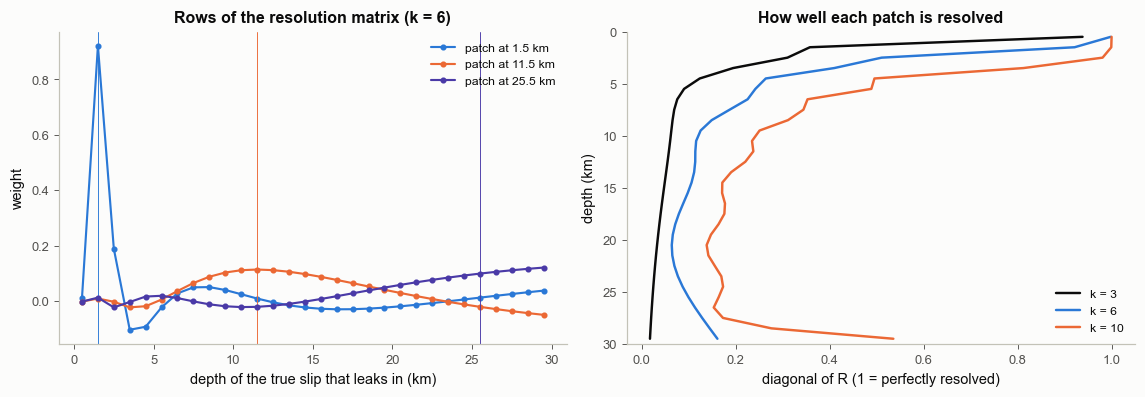

In [15]:
k_res = 6
R = Vt[:k_res].T @ Vt[:k_res]
print(f"truncated SVD with k = {k_res}: trace(R) = {np.trace(R):.2f}")
for j in [1, 11, 25]:
    print(f"patch at {zc[j]:4.1f} km: diagonal R_jj = {R[j, j]:.3f}, row sums to {R[j].sum():.3f}, kernel peak at {zc[np.argmax(R[j])]:.1f} km")
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.7))
for j, c in zip([1, 11, 25], [S.BLUE, S.ORANGE, S.VIOLET]):
    axs[0].plot(zc, R[j], "o-", color=c, ms=3, lw=1.4, label=f"patch at {zc[j]:.1f} km")
    axs[0].axvline(zc[j], color=c, lw=0.6)
axs[0].set_xlabel("depth of the true slip that leaks in (km)"); axs[0].set_ylabel("weight")
axs[0].set_title(f"Rows of the resolution matrix (k = {k_res})")
axs[0].legend(fontsize=8)
for k, c in [(3, S.INK), (6, S.BLUE), (10, S.ORANGE)]:
    Rk = Vt[:k].T @ Vt[:k]
    axs[1].plot(np.diag(Rk), zc, color=c, lw=1.6, label=f"k = {k}")
axs[1].set_ylim(30, 0); axs[1].set_xlabel("diagonal of R (1 = perfectly resolved)"); axs[1].set_ylabel("depth (km)")
axs[1].set_title("How well each patch is resolved")
axs[1].legend(fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-07_resolution")
plt.show()

**How to read it.** Left: the shallow kernel is a narrow peak at its own depth; the deep kernel is low and broad, so
the estimate at that depth is an average over many kilometres. Right: keeping more channels sharpens resolution
(diagonal closer to 1), but section 5 showed the price: more noise. **Resolution and variance trade off**, and no
choice of $k$ gives both. Least squares alone cannot make that choice in a principled way; a prior can (2.08, 2.09).

**Common misreadings.**
* *"A well-resolved patch has a small uncertainty."* Better resolution comes with more noise; the two must be read
  together.
* *"Resolution is a property of the data alone."* It depends on the data and on the regularisation or prior.

**In geodesy.** Checkerboard and spike tests in slip inversions (inverting synthetic data made from a known
checkerboard or single-patch slip, and seeing how much of it comes back) probe exactly these rows. Notebook 2.33 shows the
resolution matrix for Bayesian priors, and 2.08 shows the Bayesian counterpart: posterior versus prior standard
deviation patch by patch.

## 7. Computing it: solve, do not invert

**In plain words.** The formulas above contain inverses such as $(\mathbf G^\top\mathbf C_d^{-1}\mathbf G)^{-1}$. They
are for reading, not for typing into a computer. Forming an inverse explicitly, or even forming
$\mathbf G^\top\mathbf G$, throws away accuracy when the problem is close to singular. Computers should instead
*solve* the system with a factorisation of $\mathbf G$ itself.

**Precisely.** Three steps make weighted least squares stable:
1. **Whiten**: factor $\mathbf C_d = \mathbf L\mathbf L^\top$ (Cholesky factorisation, 2.06) and replace $\mathbf G, \mathbf d$ by
   $\mathbf L^{-1}\mathbf G, \mathbf L^{-1}\mathbf d$, computed with a triangular solve (solving with the triangular
   $\mathbf L$ needs only substitution, row by row, never an inverse). Weighted least squares becomes ordinary least
   squares with unit noise (whitening, 2.06).
2. **Factor $\mathbf G$, not $\mathbf G^\top\mathbf G$**: QR (2.06: $\mathbf G = \mathbf Q\mathbf R$ with orthonormal columns in
   $\mathbf Q$ and a triangular $\mathbf R$) or SVD of the whitened $\mathbf G$ (`np.linalg.lstsq` uses the SVD). The
   normal equations square the **condition number** $\kappa$ (the ratio of the largest to the smallest singular value,
   which says how many digits a solve can lose): if $\kappa(\mathbf G) = 10^8$, then $\kappa(\mathbf G^\top\mathbf G) = 10^{16}$,
   at the limit of double precision (the roughly 16 significant digits a computer stores).
3. **Never form an inverse** unless you need its entries (the posterior covariance is the one common case).

**Worked example.** A degree-11 polynomial trend over three years of positions (36 monthly epochs) has a nearly
singular design matrix. We make exact, noise-free data from known coefficients and ask each method to recover them.
Any error is pure round-off.

condition number of the whitened G: 1.32e+08;  of G^T Cd^-1 G: 1.75e+16
explicit inverse of Gᵀ C_d⁻¹ G    : relative error of the recovered coefficients 3.4e-01
solve the normal equations        : relative error of the recovered coefficients 3.3e-03
whiten, then QR of G              : relative error of the recovered coefficients 3.3e-09
whiten, then SVD (lstsq)          : relative error of the recovered coefficients 1.1e-09


saved figures/2-07_solve_not_invert.png


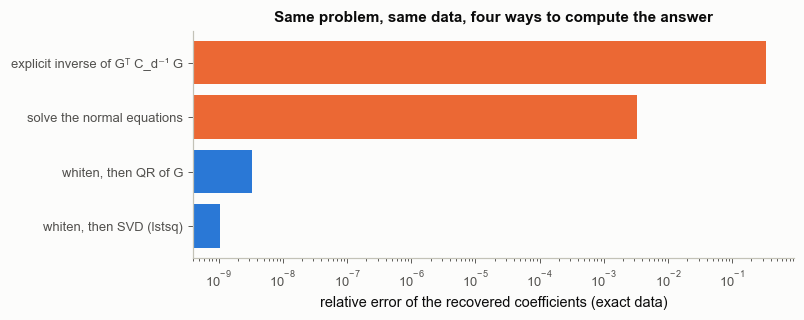

In [16]:
import scipy.linalg as sla
tp = np.linspace(0.0, 3.0, 36) / 3.0                          # time scaled to [0, 1]
Gp = np.vander(tp, 12, increasing=True)                        # columns 1, t, t^2, ..., t^11
m_p = np.random.default_rng(3).standard_normal(12)
sig_p = np.where(np.arange(36) % 4 == 0, 3.0, 1.0)            # every fourth epoch noisier: a real C_d
Cd_p = np.diag(sig_p ** 2)
d_p = Gp @ m_p                                                 # exact data: any error below is round-off
Ci = np.linalg.inv(Cd_p)
sv = np.linalg.svd(Gp / sig_p[:, None], compute_uv=False)
print(f"condition number of the whitened G: {sv[0] / sv[-1]:.2e};  of G^T Cd^-1 G: {(sv[0] / sv[-1]) ** 2:.2e}")
Lp = np.linalg.cholesky(Cd_p)
Gw, dw = sla.solve_triangular(Lp, Gp, lower=True), sla.solve_triangular(Lp, d_p, lower=True)
methods = {
    "explicit inverse of Gᵀ C_d⁻¹ G": np.linalg.inv(Gp.T @ Ci @ Gp) @ (Gp.T @ Ci @ d_p),
    "solve the normal equations": np.linalg.solve(Gp.T @ Ci @ Gp, Gp.T @ Ci @ d_p),
    "whiten, then QR of G": sla.solve_triangular(*(lambda q, r: (r, q.T @ dw))(*np.linalg.qr(Gw)), lower=False),
    "whiten, then SVD (lstsq)": np.linalg.lstsq(Gw, dw, rcond=None)[0],
}
rel_err = {k: np.linalg.norm(v - m_p) / np.linalg.norm(m_p) for k, v in methods.items()}
for k, v in rel_err.items():
    print(f"{k:34s}: relative error of the recovered coefficients {v:.1e}")

fig, ax = plt.subplots(figsize=(7.4, 3.0))
names = list(rel_err)
ax.barh(names[::-1], [rel_err[k] for k in names[::-1]], color=[S.BLUE, S.BLUE, S.ORANGE, S.ORANGE])
ax.set_xscale("log"); ax.set_xlabel("relative error of the recovered coefficients (exact data)")
ax.set_title("Same problem, same data, four ways to compute the answer", fontsize=10)
fig.tight_layout()
bk.savefig(fig, "2-07_solve_not_invert")
plt.show()

**How to read it.** The data are exact, so every error is round-off. The two routes through
$\mathbf G^\top\mathbf C_d^{-1}\mathbf G$ (orange) lose many more digits than the routes that factor the whitened
$\mathbf G$ itself (blue); the printed condition numbers say why. With noisy data the lost digits would add to the
noise without warning.

**Common misreadings.**
* *"`inv` and `solve` give the same answer."* In exact arithmetic, yes. In floating point they differ, here by orders
  of magnitude (printed). Solving with a factorisation is the safe default; an explicit inverse is worth forming only
  when its entries are needed, as for a posterior covariance.
* *"Whitening changes the problem."* It is the same problem written in units of the noise: the estimate and its
  covariance are identical, and every residual is then directly in noise units.

Next: [**2.08 · Bayesian linear inversion and the MAP**](2-08_bayesian_linear_map.ipynb).